# Wave-CAIPI 3D gradient echo

A Wave-CAIPI acquisition plays a sinusoid on one phase-encoding axis and a cosinusoid on the
other **while the ADC samples**. Each readout then traces a corkscrew about its Cartesian line,
which spreads every voxel along the readout by an amount that depends on where the voxel is in
`y` and `z`. With a CAIPI-shifted undersampling pattern, that spreading is what lets the coil
array separate the aliased copies.

This notebook builds a flow-compensated, RF-spoiled 3D Wave-CAIPI GRE from public SeqCraft
pieces, writes it, and checks it on the **compiled and written** sequence. Ownership follows
the module's contract:

| | owned by |
|---|---|
| readout lobe, ADC, oversampling, Wave gradients and their ramps, the centring moment (stated) | `WaveReadout` |
| the `(line, partition)` table, the CAIPI pattern, labels, RF spoiling, TE and TR | this notebook |
| slab rephasing, LIN/PAR encoding, the Wave's stated moment and flow compensation, merged into one lobe per axis | `PhysicalDesignScope` |
| rewinders and the spoiler after the readout | this notebook, from the readout's stated `area_after_echo_per_m` |

A no-Wave twin -- the same composition with a `CartesianLine` -- and a prospectively
undersampled R = 2 x 2 CAIPI version of both are built alongside.
[`02_simulate_and_reconstruct`](02_simulate_and_reconstruct.ipynb) simulates the written files.

In [1]:
import warnings

warnings.filterwarnings('ignore', message='IProgress not found')   # tqdm, on import

from pathlib import Path
from types import SimpleNamespace

import numpy as np
import pypulseq as pp

import seqcraft as sc
from seqcraft.design.events import knots_of, pwl_moment

opts = pp.Opts(
    max_grad=40, grad_unit='mT/m',
    max_slew=150, slew_unit='T/m/s',
    B0=3.0,
    rf_dead_time=100e-6,
    rf_ringdown_time=30e-6,
    adc_dead_time=10e-6,
)

FOV_MM = (200.0, 200.0, 120.0)      # x readout, y lines (sine), z partitions (cosine)
MATRIX = (32, 32, 8)
SLAB_MM, FLIP_DEG = 140.0, 12.0
DUMMIES = 200                       # spoiled steady state to ~1 % for T1 up to 4 s at 12 deg
OVERSAMPLING, DWELL_S = 4, 20e-6    # ADC samples per pixel, and the ADC's own dwell
CYCLES, WAVE_MT_M = 7, 3.5          # the Wave prescription
ACCELERATION, CAIPI_SHIFT = (2, 2), 1

NX, NY, NZ = MATRIX
SEQ_DIR = Path('seq')
SEQ_DIR.mkdir(exist_ok=True)
print(f'{NX} x {NY} x {NZ} over {FOV_MM} mm; readout x, sine y, cosine z')

32 x 32 x 8 over (200.0, 200.0, 120.0) mm; readout x, sine y, cosine z


## The readout

`prephase=False`, because the scope below merges the readout's centring moment with the
encoding and flow compensation instead of playing it separately. The module still **states**
that moment, and still emits the cosine's entrance and exit ramps.

In [2]:
wave = sc.modules.WaveReadout(
    opts=opts, fov_mm=FOV_MM[0], matrix=NX, dwell_s=DWELL_S, oversampling=OVERSAMPLING,
    cycles=CYCLES, amplitude_mT_m=WAVE_MT_M, axis='x', sine_axis='y', cosine_axis='z',
    centering='sinzero', prephase=False)
plain = sc.modules.CartesianLine(
    opts=opts, fov_mm=FOV_MM[0], matrix=NX, dwell_s=DWELL_S, oversampling=OVERSAMPLING,
    axis='x', prephase=False)

N = wave.line.num_samples
ECHO = wave.line.echo_sample(0)
G0 = wave.amplitude_mT_m * 1e-3 * float(opts.gamma)
G_READ = float(wave.line.gx.amplitude)
print(f'ADC: {N} samples ({OVERSAMPLING} per pixel) at {wave.line.dwell_s * 1e6:.1f} us, '
      f'window {wave.window_s * 1e3:.3f} ms, echo sample {ECHO}')
print(f'Wave: {CYCLES} cycles, G0 = {wave.amplitude_mT_m:.3f} mT/m, period '
      f'{wave.window_s / CYCLES * 1e6:.1f} us, peak slew '
      f'{G0 * wave.angular_frequency_rad_s / float(opts.gamma):.1f} T/m/s')
for axis in 'xyz':
    print(f'  stated moment {axis}: {wave.prephaser_area_per_m(axis):9.3f} 1/m   '
          f'echo offset {wave.echo_offset_per_m(axis):6.3f}   '
          f'after the echo {wave.area_after_echo_per_m(axis):9.3f} 1/m')

# The spreading a voxel at (y, z) sees along x is up to G0 * |(y, z)| / G_read.  It has to stay
# inside the oversampled FOV with the object, which is what the oversampling buys.
corner_m = np.hypot(FOV_MM[1], FOV_MM[2]) / 2e3
print(f'largest voxel spreading {G0 * corner_m / G_READ * 1e3:.0f} mm, inside the '
      f'+/-{OVERSAMPLING * FOV_MM[0] / 2:.0f} mm oversampled readout FOV')

ADC: 128 samples (4 per pixel) at 20.0 us, window 2.560 ms, echo sample 64
Wave: 7 cycles, G0 = 3.500 mT/m, period 365.7 us, peak slew 60.1 T/m/s
  stated moment x:   -80.938 1/m   echo offset  0.000   after the echo    79.688 1/m
  stated moment y:   -17.177 1/m   echo offset  0.000   after the echo   -17.177 1/m
  stated moment z:    -0.756 1/m   echo offset  0.000   after the echo     3.714 1/m
largest voxel spreading 278 mm, inside the +/-400 mm oversampled readout FOV


## Encoding: the caller's table, `PhaseEncode`'s arithmetic

The fully sampled table walks partitions in the outer loop. The CAIPI table keeps every second
line and every second partition, shifting the kept partition by one on alternate kept lines.

In [3]:
pe = {'y': sc.modules.PhaseEncode(opts=opts, fov_mm=FOV_MM[1], matrix=NY, axis='y'),
      'z': sc.modules.PhaseEncode(opts=opts, fov_mm=FOV_MM[2], matrix=NZ, axis='z')}


def encoded(state, axis):
    """The k the encoding puts on `axis` for ``state = (line, partition, ...)``, 1/m."""
    index = {'y': state[0], 'z': state[1]}.get(axis)
    return 0.0 if index is None else pe[axis].k_per_m(index)


FULL = [(line, part) for part in range(NZ) for line in range(NY)]
ry, rz = ACCELERATION
CAIPI = [(line, start + ((line // ry) * CAIPI_SHIFT) % rz)
         for start in range(0, NZ, rz) for line in range(0, NY, ry)]

grid = np.full((NZ, NY), '.')
for line, part in CAIPI:
    grid[part, line] = 'o'
print(f'CAIPI R = {ry} x {rz}, shift {CAIPI_SHIFT}: {len(CAIPI)} of {len(FULL)} lines '
      f'(rows: partition, columns: line)')
print('\n'.join(''.join(row) for row in grid))

CAIPI R = 2 x 2, shift 1: 64 of 256 lines (rows: partition, columns: line)
o...o...o...o...o...o...o...o...
..o...o...o...o...o...o...o...o.
o...o...o...o...o...o...o...o...
..o...o...o...o...o...o...o...o.
o...o...o...o...o...o...o...o...
..o...o...o...o...o...o...o...o.
o...o...o...o...o...o...o...o...
..o...o...o...o...o...o...o...o.


## One repetition

`before` and `after` are functions of the state, which is `(line, partition, rf_phase,
acquire)`. That is how the RF-spoiling phase reaches the excitation and the receiver, which
have to carry the same one. The scope solves one window on x, y and z for the whole family:
the slab rephaser, the encode, the readout's stated moment and first-moment nulling at the
echo, with every state sharing one TE.

After the readout, y and z are rewound to zero using the readout's stated after-echo moment,
and x is spoiled.

In [4]:
def phase_deg(n, increment=117.0):
    """The standard quadratic RF-spoiling schedule, counted from the first dummy."""
    return 0.5 * increment * n * (n + 1)


exc = sc.modules.Excitation(opts=opts, flip_deg=FLIP_DEG, thickness_mm=SLAB_MM, axis='z',
                            duration_s=1e-3)
spoil = sc.modules.spoiler(opts, cycles_per_voxel=2.0, voxel_mm=FOV_MM[0] / NX, axis='x')


def stated(readout):
    """``(echo offset, area after the echo)`` per axis, as the readout states them."""
    if isinstance(readout, sc.modules.WaveReadout):
        return ({a: readout.echo_offset_per_m(a) for a in 'xyz'},
                {a: readout.area_after_echo_per_m(a) for a in 'xyz'})
    return ({a: 0.0 for a in 'xyz'},
            {a: readout.area_after_echo_per_m if a == readout.axis else 0.0 for a in 'xyz'})


def acquisition(readout, table, *, te_s=None, tr_s=None, flow=True):
    """One acquisition: dummies, then one repetition per ``(line, partition)`` in `table`."""
    offset, after = stated(readout)
    states = ([(*table[0], phase_deg(n), False) for n in range(DUMMIES)]
              + [(*entry, phase_deg(DUMMIES + i), True) for i, entry in enumerate(table)])
    corners = [s for s in states if s[3] and s[0] in (0, NY - 2, NY - 1)
               and s[1] in (0, NZ - 2, NZ - 1)]
    scope = sc.PhysicalDesignScope(
        origin_s=exc.time_to_center(),
        before=lambda s: exc(rephase=False, phase_deg=s[2]),
        after=lambda s: readout(acquire=s[3], phase_deg=s[2]),
        echo_in_after_s=readout.time_to_echo(), axes=('x', 'y', 'z'), states=states,
        design_states=corners,
        k_at_echo=lambda s, a: encoded(s, a) + offset[a])
    design = scope.design(opts=opts, flow_comp=sc.FlowCompensation(axis=('x', 'y', 'z'))
                          if flow else None)
    if te_s is not None and te_s > design.te_s + 1e-12:
        design = design.at(te_s=te_s)

    def rewind(state, axis):
        return -(encoded(state, axis) + offset[axis] + after[axis])

    worst = max(abs(rewind(s, a)) for s in states for a in 'yz')
    tail = sc.Raster(opts.grad_raster_time).ceil(max(
        pp.calc_duration(pp.make_trapezoid('y', area=worst, system=opts)), spoil.duration))

    def repetition(state):
        out = sc.LogicBlock('repetition')
        body = design.build(state)
        out.add(0.0, body)
        out.add(body.duration, spoil)
        for axis in 'yz':
            if abs(rewind(state, axis)) > 1e-9:
                out.add(body.duration, pp.make_trapezoid(axis, area=rewind(state, axis),
                                                         duration=tail, system=opts))
        if state[3]:
            out.add(0.0, pp.make_label(type='SET', label='LIN', value=int(state[0])))
            out.add(0.0, pp.make_label(type='SET', label='PAR', value=int(state[1])))
        return out

    blocks = [repetition(s) for s in states]
    shortest = sc.Raster(opts.block_duration_raster).ceil(max(b.duration for b in blocks))
    tr = shortest if tr_s is None else tr_s
    assert tr >= shortest, 'TR below this acquisition\'s shortest'
    tree = sc.LogicBlock('scan')
    for n, block in enumerate(blocks):
        tree.add(n * tr, block)
    return SimpleNamespace(tree=tree, te_s=design.te_s, tr_s=tr, shortest_tr_s=shortest,
                           table=table, readout=readout, offset=offset, states=states,
                           repetition=repetition)


first = {name: acquisition(r, FULL) for name, r in (('wave', wave), ('plain', plain))}
TE = max(a.te_s for a in first.values())
TR = sc.Raster(opts.block_duration_raster).ceil(
    max(a.shortest_tr_s for a in first.values()) + 100e-6)
acq = {f'{name}_{size}': acquisition(r, table, te_s=TE, tr_s=TR)
       for name, r in (('wave', wave), ('plain', plain))
       for size, table in (('full', FULL), ('caipi', CAIPI))}
for name, a in acq.items():
    print(f'{name:12s} TE {a.te_s * 1e3:.3f} ms  TR {a.tr_s * 1e3:.3f} ms  '
          f'{len(a.table)} lines + {DUMMIES} dummies = {a.tree.duration:.2f} s')
print(f'own shortest TE: Wave {first["wave"].te_s * 1e3:.3f} ms, '
      f'no-Wave {first["plain"].te_s * 1e3:.3f} ms')

wave_full    TE 2.620 ms  TR 5.080 ms  256 lines + 200 dummies = 2.32 s
wave_caipi   TE 2.620 ms  TR 5.080 ms  64 lines + 200 dummies = 1.34 s
plain_full   TE 2.620 ms  TR 5.080 ms  256 lines + 200 dummies = 2.32 s
plain_caipi  TE 2.620 ms  TR 5.080 ms  64 lines + 200 dummies = 1.34 s
own shortest TE: Wave 2.620 ms, no-Wave 2.590 ms


One acquired repetition, as the compiler sees it. The cosine (z) leaves rest before the ADC
opens and ramps back down as soon as the window closes; the sine (y) starts and ends with the
window.

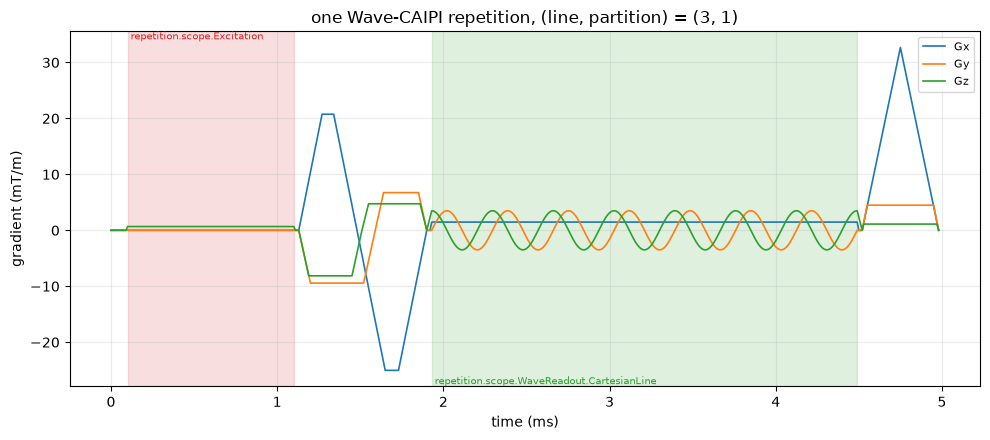

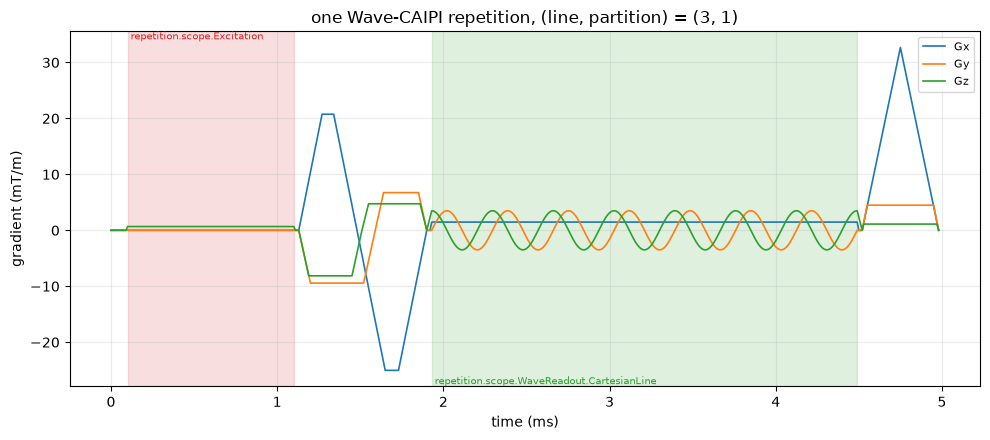

In [5]:
example = acq['wave_full'].states[DUMMIES + NY + 3]
sc.plot_block(acq['wave_full'].repetition(example), opts,
              title=f'one Wave-CAIPI repetition, (line, partition) = {example[:2]}')

## Compile, check timing, write

The compiler reports two kinds of warning here, both expected, and they are counted rather
than printed:

- **same-axis merges**: the scope's lobes overlap the excitation's slab-select ramp and the
  readout's events on the same axis, and are summed exactly into one gradient per axis;
- **vector-norm**: three axes ramping together exceed the per-axis slew in vector magnitude,
  which the compiler reports as informational. The per-axis limits, which are what is
  enforced, are printed below.

In [6]:
seqs = {}
for name, a in acq.items():
    with warnings.catch_warnings(record=True) as caught:
        warnings.simplefilter('always', sc.SeqCraftWarning)
        seqs[name] = sc.compile(a.tree, opts, name=f'wave_caipi_gre_3d_{name}', definitions={
            'FOV': [v / 1e3 for v in FOV_MM], 'Matrix': list(MATRIX),
            'ReadoutOversamplingFactor': OVERSAMPLING, 'TE': a.te_s, 'TR': a.tr_s,
            'WaveCycles': CYCLES if name.startswith('wave') else 0,
            'WaveAmplitude_mT_m': wave.amplitude_mT_m if name.startswith('wave') else 0.0,
        })
    kinds = sorted({str(w.message).split(':')[0] for w in caught})
    ok, report = seqs[name].check_timing()
    path = SEQ_DIR / f'wave_caipi_gre_3d_{name}.seq'
    seqs[name].write(str(path))
    print(f'{name:12s} {len(seqs[name].block_events):5d} blocks  check_timing {ok}  '
          f'({len(report)} reports)  -> {path}\n{"":12s} warnings: {"; ".join(kinds)}')
    assert ok


def peaks(seq):
    """Largest |g| and |slew| per axis over the compiled sequence, from the emitted knots."""
    grad, slew = {a: 0.0 for a in 'xyz'}, {a: 0.0 for a in 'xyz'}
    for b in seq.block_events:
        block = seq.get_block(b)
        for a in 'xyz':
            event = getattr(block, f'g{a}', None)
            if event is not None:
                t, g = knots_of(event)
                grad[a] = max(grad[a], float(np.max(np.abs(g))))
                if t.size > 1:
                    slew[a] = max(slew[a], float(np.max(np.abs(np.diff(g) / np.diff(t)))))
    return grad, slew


grad, slew = peaks(seqs['wave_full'])
to_mT, to_T = 1e3 / float(opts.gamma), 1 / float(opts.gamma)
print('Wave, full: peak ' + ', '.join(f'{a} {grad[a] * to_mT:.2f} mT/m' for a in 'xyz')
      + ' | slew ' + ', '.join(f'{a} {slew[a] * to_T:.1f} T/m/s' for a in 'xyz'))

wave_full     2279 blocks  check_timing True  (0 reports)  -> seq/wave_caipi_gre_3d_wave_full.seq
             warnings: 1368 same-axis gradient merges; 904 blocks over the vector-norm limit (legal on real amplifiers)


wave_caipi    1583 blocks  check_timing True  (0 reports)  -> seq/wave_caipi_gre_3d_wave_caipi.seq
             warnings: 526 blocks over the vector-norm limit (legal on real amplifiers); 792 same-axis gradient merges


plain_full    2735 blocks  check_timing True  (0 reports)  -> seq/wave_caipi_gre_3d_plain_full.seq
             warnings: 1360 same-axis gradient merges; 907 blocks over the vector-norm limit (legal on real amplifiers)


plain_caipi   1583 blocks  check_timing True  (0 reports)  -> seq/wave_caipi_gre_3d_plain_caipi.seq
             warnings: 527 blocks over the vector-norm limit (legal on real amplifiers); 788 same-axis gradient merges
Wave, full: peak x 32.68 mT/m, y 25.04 mT/m, z 10.21 mT/m | slew x 148.2 T/m/s, y 149.6 T/m/s, z 149.9 T/m/s


## What was encoded, read off the compiled sequence

For every acquired repetition, k at the echo sample has to equal the encoding target plus the
readout's stated echo offset (zero here, under `'sinzero'`). The whole readout, minus its target,
has to equal `WaveReadout.k_per_m()` at every sample. That is the module's nominal trajectory,
and it must be what the composition actually plays.

In [7]:
def targets(a):
    """``(3, lines)`` encoding target plus the readout's stated echo offset."""
    return np.array([[encoded(entry, axis) + a.offset[axis] for entry in a.table]
                     for axis in 'xyz'])


def per_line(k_adc, a):
    return np.asarray(k_adc).reshape(3, len(a.table), N)


nominal = {'wave': wave.k_per_m(),
           'plain': np.vstack([(np.arange(N) - ECHO) * plain.dk_per_m / OVERSAMPLING,
                               np.zeros(N), np.zeros(N)])}
compiled = {}
warnings.filterwarnings('ignore', category=sc.SeqCraftWarning)     # counted above
for name, a in acq.items():
    compiled[name] = sc.kspace(a.tree, opts)
    k = per_line(compiled[name]['k_adc'], a) - targets(a)[:, :, None]
    at_echo = np.max(np.abs(k[:, :, ECHO]), axis=1)
    against = np.max(np.abs(k - nominal[name.split('_')[0]][:, None, :]))
    print(f'{name:12s} |k at echo - target| x {at_echo[0]:.1e} y {at_echo[1]:.1e} '
          f'z {at_echo[2]:.1e} 1/m;  |k - target - k_per_m| {against:.1e} 1/m')
    assert np.max(at_echo) < 1e-6 and against < 1e-5

wave_full    |k at echo - target| x 6.1e-10 y 5.0e-10 z 1.6e-09 1/m;  |k - target - k_per_m| 1.6e-09 1/m


wave_caipi   |k at echo - target| x 8.1e-10 y 3.1e-10 z 2.0e-09 1/m;  |k - target - k_per_m| 2.0e-09 1/m


plain_full   |k at echo - target| x 4.7e-10 y 1.3e-10 z 2.7e-10 1/m;  |k - target - k_per_m| 4.9e-10 1/m


plain_caipi  |k at echo - target| x 2.0e-10 y 7.1e-11 z 1.0e-10 1/m;  |k - target - k_per_m| 2.2e-10 1/m


## The written file, read back

Each `.seq` is read back with PyPulseq. Its sample times and its trajectory from
`calculate_kspacePP` are compared with the compiled ones. Labels are read back too, so that a
reconstruction sorting by `LIN`/`PAR` finds the table this notebook wrote.

In [8]:
readback = {}
for name, a in acq.items():
    back = pp.Sequence(system=opts)
    back.read(str(SEQ_DIR / f'wave_caipi_gre_3d_{name}.seq'))
    k_back, t_back = (np.asarray(v) for v in back.calculate_kspacePP()[:2])
    labels = back.evaluate_labels(evolution='adc')          # one value per ADC event
    lin, par = np.asarray(labels['LIN']), np.asarray(labels['PAR'])
    readback[name] = SimpleNamespace(seq=back, k=k_back, t=t_back)
    dt = np.max(np.abs(t_back - compiled[name]['t_adc']))
    dk = np.max(np.abs(k_back - compiled[name]['k_adc']))
    scale = np.max(np.abs(compiled[name]['k_adc']))
    labels_ok = (list(lin) == [e[0] for e in a.table]) and (list(par) == [e[1] for e in a.table])
    print(f'{name:12s} t_adc {dt:.1e} s;  k {dk:.1e} 1/m ({dk / scale:.1e} of max |k|);  '
          f'LIN/PAR labels match the table: {labels_ok}')
    assert dt < 1e-9 and dk / scale < 1e-5 and labels_ok

wave_full    t_adc 2.2e-16 s;  k 1.4e-04 1/m (1.5e-06 of max |k|);  LIN/PAR labels match the table: True


wave_caipi   t_adc 2.2e-16 s;  k 2.4e-04 1/m (2.4e-06 of max |k|);  LIN/PAR labels match the table: True
plain_full   t_adc 0.0e+00 s;  k 5.3e-05 1/m (6.6e-07 of max |k|);  LIN/PAR labels match the table: True
plain_caipi  t_adc 0.0e+00 s;  k 5.3e-05 1/m (6.6e-07 of max |k|);  LIN/PAR labels match the table: True


## Flow compensation, measured on the written file

The claim is first-moment nulling **at the echo sample**, about the RF centre, on x, y and z,
for every repetition. It includes the Wave's own contribution up to the echo. It is measured
by integrating `g(t)·(t − t_RF)` over the read-back gradient knots. For scale, the same
acquisition designed without `FlowCompensation` is measured the same way.

In [9]:
def moments_at_echo(seq, t_echo):
    """``(order 0, order 1)`` per axis, about each repetition's RF centre, to its echo sample."""
    ids = list(seq.block_events)
    starts = np.cumsum([0.0] + [seq.block_durations[b] for b in ids])[:-1]
    rf_centres, knots = [], {}
    for s, b in zip(starts, ids):
        block = seq.get_block(b)
        if block.rf is not None:
            rf_centres.append(s + float(block.rf.delay) + float(pp.calc_rf_center(block.rf)[0]))
        for axis in 'xyz':
            event = getattr(block, f'g{axis}', None)
            if event is not None:
                knots[(b, axis)] = knots_of(event, s)
    rf_centres = np.asarray(rf_centres)
    out = np.zeros((2, 3, len(t_echo)))
    for i, te in enumerate(t_echo):
        t_rf = rf_centres[rf_centres < te].max()
        first = max(0, int(np.searchsorted(starts, t_rf, side='right')) - 1)
        last = int(np.searchsorted(starts, te, side='left'))
        for b in ids[first:last]:
            for row, axis in enumerate('xyz'):
                if (b, axis) not in knots:
                    continue
                t, g = knots[(b, axis)]
                if t[-1] <= t_rf or t[0] >= te:
                    continue
                inside = (t > t_rf) & (t < te)
                tt = np.concatenate([[max(t[0], t_rf)], t[inside], [min(t[-1], te)]])
                gg = np.interp(tt, t, g)
                out[0, row, i] += pwl_moment(tt, gg, 0)
                out[1, row, i] += pwl_moment(tt - t_rf, gg, 1)
    return out


uncompensated = acquisition(wave, FULL[:NY], flow=False)
with_fc = moments_at_echo(readback['wave_full'].seq,
                          readback['wave_full'].t.reshape(-1, N)[:, ECHO])
seq_nofc = sc.compile(uncompensated.tree, opts)
k_nofc = sc.kspace(uncompensated.tree, opts)
without_fc = moments_at_echo(seq_nofc, np.asarray(k_nofc['t_adc']).reshape(-1, N)[:, ECHO])
print('largest |m1| at the echo, s/m (1/m * s), over every repetition:')
for row, axis in enumerate('xyz'):
    print(f'  {axis}: with FlowCompensation {np.max(np.abs(with_fc[1, row])):.2e}   '
          f'without (first {NY} lines) {np.max(np.abs(without_fc[1, row])):.2e}')
print(f'm0 at the echo minus the target, worst axis: '
      f'{np.max(np.abs(with_fc[0] - targets(acq["wave_full"]))):.1e} 1/m')
assert np.max(np.abs(with_fc[1])) < 1e-3 * np.max(np.abs(without_fc[1]))

largest |m1| at the echo, s/m (1/m * s), over every repetition:
  x: with FlowCompensation 6.48e-08   without (first 32 lines) 6.45e-02
  y: with FlowCompensation 1.01e-07   without (first 32 lines) 6.27e-02
  z: with FlowCompensation 5.70e-09   without (first 32 lines) 3.05e-02
m0 at the echo minus the target, worst axis: 1.4e-04 1/m


## The CAIPI files play the full files' repetitions

A prospectively undersampled repetition should be the fully sampled one at the same
`(line, partition)`, gradient for gradient. Only its RF-spoiling phase differs, because that is
counted per repetition. That is checked on the compiled trajectories.

In [10]:
for name in ('wave', 'plain'):
    full, caipi = acq[f'{name}_full'], acq[f'{name}_caipi']
    k_full = per_line(compiled[f'{name}_full']['k_adc'], full)
    k_caipi = per_line(compiled[f'{name}_caipi']['k_adc'], caipi)
    rows = [full.table.index(entry) for entry in caipi.table]
    print(f'{name:6s} CAIPI vs the same lines of the full file: '
          f'{np.max(np.abs(k_caipi - k_full[:, rows])):.1e} 1/m')
    assert np.max(np.abs(k_caipi - k_full[:, rows])) < 1e-6

wave   CAIPI vs the same lines of the full file: 1.8e-09 1/m
plain  CAIPI vs the same lines of the full file: 2.8e-10 1/m


## What `02` reads

In [11]:
np.savez(
    SEQ_DIR / 'wave_caipi_gre_3d_nominal.npz',
    fov_mm=np.array(FOV_MM), matrix=np.array(MATRIX), oversampling=OVERSAMPLING,
    dwell_s=wave.line.dwell_s, echo_sample=ECHO, dummies=DUMMIES, te_s=TE, tr_s=TR,
    cycles=CYCLES, amplitude_mT_m=wave.amplitude_mT_m,
    full=np.array(FULL), caipi=np.array(CAIPI),
    wave_k_per_m=wave.k_per_m(), wave_sample_times_s=wave.sample_times_s(),
    encoded_y=np.array([pe['y'].k_per_m(i) for i in range(NY)]),
    encoded_z=np.array([pe['z'].k_per_m(i) for i in range(NZ)]),
)
print(sorted(p.name for p in SEQ_DIR.iterdir()))

['wave_caipi_gre_3d_nominal.npz', 'wave_caipi_gre_3d_plain_caipi.seq', 'wave_caipi_gre_3d_plain_full.seq', 'wave_caipi_gre_3d_wave_caipi.seq', 'wave_caipi_gre_3d_wave_full.seq']


## Summary

| | |
|---|---|
| a Wave-CAIPI repetition is **public pieces composed** | `Excitation(rephase=False)`, one `PhysicalDesignScope` window, `WaveReadout(prephase=False)`, rewinders |
| the readout states its centring moment; the scope delivers it | k at the echo sample on target in every repetition of all four files |
| `k_per_m()` is what the file plays | every sample of every repetition, compiled and read back |
| flow compensation includes the Wave | first moment at the echo nulled on x, y and z, measured on the written file |
| the CAIPI pattern is the caller's | a table and a shift in this notebook; the CAIPI files replay the full files' repetitions |

What this notebook does not show is that the Wave encodes anything an image could use. That is
[`02`](02_simulate_and_reconstruct.ipynb).